# 04. XAI Interpretation

## Objective

Explain the already-frozen CoxNet models without any additional
feature selection or hyperparameter tuning.

Primary model:
- Clinical + RNA

Supporting models:
- Clinical-only
- Clinical + Hallmark

Main analyses:
1. Global interpretation using non-zero CoxNet coefficients
2. Patient-specific contributions using transformed feature × coefficient
3. Supporting interpretation of clinical and Hallmark features
4. Literature-based biological interpretation of selected RNA genes/pathways

Important:
- The test set is used only for explanation of the frozen model.
- No feature or model reselection is performed based on test results.
- Coefficient directions are interpreted as model associations, not causal effects.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

# Works whether the notebook is launched from the project root
# or from the notebooks directory
cwd = Path.cwd()

if cwd.name == "notebooks":
    PROJECT_ROOT = cwd.parent
else:
    PROJECT_ROOT = cwd

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("PROCESSED_DIR:", PROCESSED_DIR)

PROJECT_ROOT: c:\kirc-genomic-prognosis
PROCESSED_DIR: c:\kirc-genomic-prognosis\data\processed


In [2]:
specs = pd.read_csv(
    PROCESSED_DIR / "final_model_specifications.csv"
)

clinical_rna_coef = pd.read_csv(
    PROCESSED_DIR / "clinical_rna_coxnet_coefficients.csv"
)

clinical_rna_nonzero = pd.read_csv(
    PROCESSED_DIR / "clinical_rna_coxnet_nonzero_features.csv"
)

clinical_rna_genes = pd.read_csv(
    PROCESSED_DIR / "clinical_rna_nonzero_genes_annotated.csv"
)

test_predictions = pd.read_csv(
    PROCESSED_DIR / "test_predictions.csv"
)

print("=== Final model specifications ===")
display(specs)

print("\n=== Clinical + RNA: all coefficients ===")
print("shape:", clinical_rna_coef.shape)
display(clinical_rna_coef.head())

print("\n=== Clinical + RNA: non-zero features ===")
print("shape:", clinical_rna_nonzero.shape)
display(clinical_rna_nonzero)

print("\n=== Annotated non-zero RNA genes ===")
print("shape:", clinical_rna_genes.shape)
display(clinical_rna_genes.head())

print("\n=== Test predictions ===")
print("shape:", test_predictions.shape)
display(test_predictions.head())

=== Final model specifications ===


,model,input,n_input_features,rna_top_k,l1_ratio,alpha_idx,cv_alpha_ratio,full_train_alpha,validation_harrell_c
0,RNA-only,RNA Top-1000 MAD genes,1000,1000.0,0.75,27,0.079060,0.019115,0.726262
1,Clinical-only,Age + Sex + Stage + Grade (10 encoded features),10,NaN,0.90,37,0.030888,0.010058,0.784003
2,Clinical+RNA,Clinical 10 + RNA Top-500 MAD genes,510,500.0,0.50,18,0.184207,0.107963,0.813516
3,Clinical+Hallmark,Clinical 10 + 50 Hallmark pathway scores,60,NaN,0.75,31,0.054287,0.021212,0.773311



=== Clinical + RNA: all coefficients ===
shape: (510, 4)


,feature,feature_type,coefficient,abs_coefficient
0,age__age,Clinical,0.000000,0.000000
1,cat__gender_FEMALE,Clinical,0.000000,0.000000
2,cat__stage_Stage II,Clinical,0.000000,0.000000
3,cat__stage_Stage III,Clinical,0.102483,0.102483
4,cat__stage_Stage IV,Clinical,0.615046,0.615046



=== Clinical + RNA: non-zero features ===
shape: (24, 4)


,feature,feature_type,coefficient,abs_coefficient
0,cat__stage_Stage IV,Clinical,0.615046,0.615046
1,cat__grade_G4,Clinical,0.144119,0.144119
2,cat__stage_Stage III,Clinical,0.102483,0.102483
3,ENSG00000147003.7,RNA,-0.102028,0.102028
4,ENSG00000184434.8,RNA,-0.074754,0.074754
5,ENSG00000119630.14,RNA,0.067019,0.067019
6,ENSG00000256235.2,RNA,0.064375,0.064375
7,ENSG00000074276.10,RNA,-0.063305,0.063305
8,ENSG00000119411.11,RNA,-0.053348,0.053348
9,ENSG00000103460.17,RNA,-0.045376,0.045376



=== Annotated non-zero RNA genes ===
shape: (21, 6)


,feature,feature_type,coefficient,abs_coefficient,gene_id,gene_name
0,ENSG00000147003.7,RNA,-0.102028,0.102028,ENSG00000147003.7,CLTRN
1,ENSG00000184434.8,RNA,-0.074754,0.074754,ENSG00000184434.8,LRRC19
2,ENSG00000119630.14,RNA,0.067019,0.067019,ENSG00000119630.14,PGF
3,ENSG00000256235.2,RNA,0.064375,0.064375,ENSG00000256235.2,SMIM3
4,ENSG00000074276.10,RNA,-0.063305,0.063305,ENSG00000074276.10,CDHR2



=== Test predictions ===
shape: (80, 7)


,patient_id,pfi_event,pfi_time,rna_only_risk,clinical_only_risk,clinical_rna_risk,clinical_pathway_risk
0,TCGA-BP-5169,0.0,193.0,1.710307,0.252957,0.877533,0.190427
1,TCGA-BP-4353,0.0,375.0,-0.848337,-0.922333,-0.038865,-0.863123
2,TCGA-BP-5200,0.0,1063.0,-0.715036,0.803049,0.010716,0.737633
3,TCGA-B0-5121,0.0,1485.0,0.645959,-0.936392,-0.341047,-0.745137
4,TCGA-B4-5378,0.0,175.0,0.639263,-0.919521,-0.091075,-0.415923


In [3]:
print("clinical_rna_coef columns:")
print(clinical_rna_coef.columns.tolist())

print("\nclinical_rna_nonzero columns:")
print(clinical_rna_nonzero.columns.tolist())

print("\nclinical_rna_genes columns:")
print(clinical_rna_genes.columns.tolist())

print("\nspecs columns:")
print(specs.columns.tolist())

print("\ntest_predictions columns:")
print(test_predictions.columns.tolist())

clinical_rna_coef columns:
['feature', 'feature_type', 'coefficient', 'abs_coefficient']

clinical_rna_nonzero columns:
['feature', 'feature_type', 'coefficient', 'abs_coefficient']

clinical_rna_genes columns:
['feature', 'feature_type', 'coefficient', 'abs_coefficient', 'gene_id', 'gene_name']

specs columns:
['model', 'input', 'n_input_features', 'rna_top_k', 'l1_ratio', 'alpha_idx', 'cv_alpha_ratio', 'full_train_alpha', 'validation_harrell_c']

test_predictions columns:
['patient_id', 'pfi_event', 'pfi_time', 'rna_only_risk', 'clinical_only_risk', 'clinical_rna_risk', 'clinical_pathway_risk']


In [4]:
print("Total non-zero features:", len(clinical_rna_nonzero))

print("\nFeature type counts:")
print(clinical_rna_nonzero["feature_type"].value_counts())

assert len(clinical_rna_nonzero) == 24, \
    f"Expected 24 non-zero features, found {len(clinical_rna_nonzero)}"

print("\nPASS: Clinical+RNA has exactly 24 non-zero features.")

Total non-zero features: 24

Feature type counts:
feature_type
RNA         21
Clinical     3
Name: count, dtype: int64

PASS: Clinical+RNA has exactly 24 non-zero features.


In [5]:
gene_annotation = (
    clinical_rna_genes[["feature", "gene_name"]]
    .drop_duplicates(subset="feature")
)

xai_global = clinical_rna_nonzero.merge(
    gene_annotation,
    on="feature",
    how="left"
)

xai_global["display_name"] = (
    xai_global["gene_name"]
    .fillna(xai_global["feature"])
)

xai_global = (
    xai_global
    .sort_values("abs_coefficient", ascending=False)
    .reset_index(drop=True)
)

xai_global["rank"] = np.arange(
    1,
    len(xai_global) + 1
)

display(
    xai_global[
        [
            "rank",
            "display_name",
            "feature",
            "feature_type",
            "coefficient",
            "abs_coefficient"
        ]
    ]
)

,rank,display_name,feature,feature_type,coefficient,abs_coefficient
0,1,cat__stage_Stage IV,cat__stage_Stage IV,Clinical,0.615046,0.615046
1,2,cat__grade_G4,cat__grade_G4,Clinical,0.144119,0.144119
2,3,cat__stage_Stage III,cat__stage_Stage III,Clinical,0.102483,0.102483
3,4,CLTRN,ENSG00000147003.7,RNA,-0.102028,0.102028
4,5,LRRC19,ENSG00000184434.8,RNA,-0.074754,0.074754
5,6,PGF,ENSG00000119630.14,RNA,0.067019,0.067019
6,7,SMIM3,ENSG00000256235.2,RNA,0.064375,0.064375
7,8,CDHR2,ENSG00000074276.10,RNA,-0.063305,0.063305
8,9,BSPRY,ENSG00000119411.11,RNA,-0.053348,0.053348
9,10,TOX3,ENSG00000103460.17,RNA,-0.045376,0.045376


In [6]:
xai_global["direction"] = np.where(
    xai_global["coefficient"] > 0,
    "Higher predicted risk",
    "Lower predicted risk"
)

display(
    xai_global[
        [
            "rank",
            "display_name",
            "feature_type",
            "coefficient",
            "direction"
        ]
    ]
)

,rank,display_name,feature_type,coefficient,direction
0,1,cat__stage_Stage IV,Clinical,0.615046,Higher predicted risk
1,2,cat__grade_G4,Clinical,0.144119,Higher predicted risk
2,3,cat__stage_Stage III,Clinical,0.102483,Higher predicted risk
3,4,CLTRN,RNA,-0.102028,Lower predicted risk
4,5,LRRC19,RNA,-0.074754,Lower predicted risk
5,6,PGF,RNA,0.067019,Higher predicted risk
6,7,SMIM3,RNA,0.064375,Higher predicted risk
7,8,CDHR2,RNA,-0.063305,Lower predicted risk
8,9,BSPRY,RNA,-0.053348,Lower predicted risk
9,10,TOX3,RNA,-0.045376,Lower predicted risk


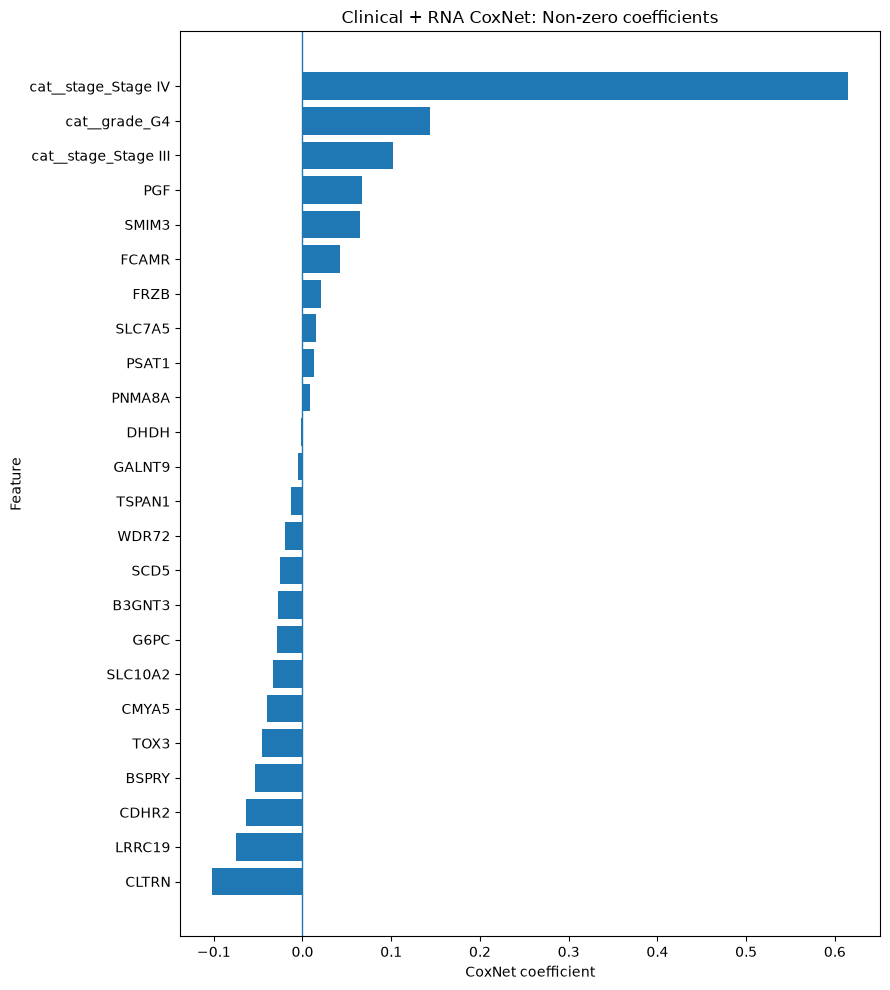

In [7]:
import matplotlib.pyplot as plt

plot_df = (
    xai_global
    .sort_values("coefficient", ascending=True)
    .copy()
)

plt.figure(figsize=(9, 10))

plt.barh(
    plot_df["display_name"],
    plot_df["coefficient"]
)

plt.axvline(0, linewidth=1)

plt.xlabel("CoxNet coefficient")
plt.ylabel("Feature")
plt.title("Clinical + RNA CoxNet: Non-zero coefficients")

plt.tight_layout()
plt.show()

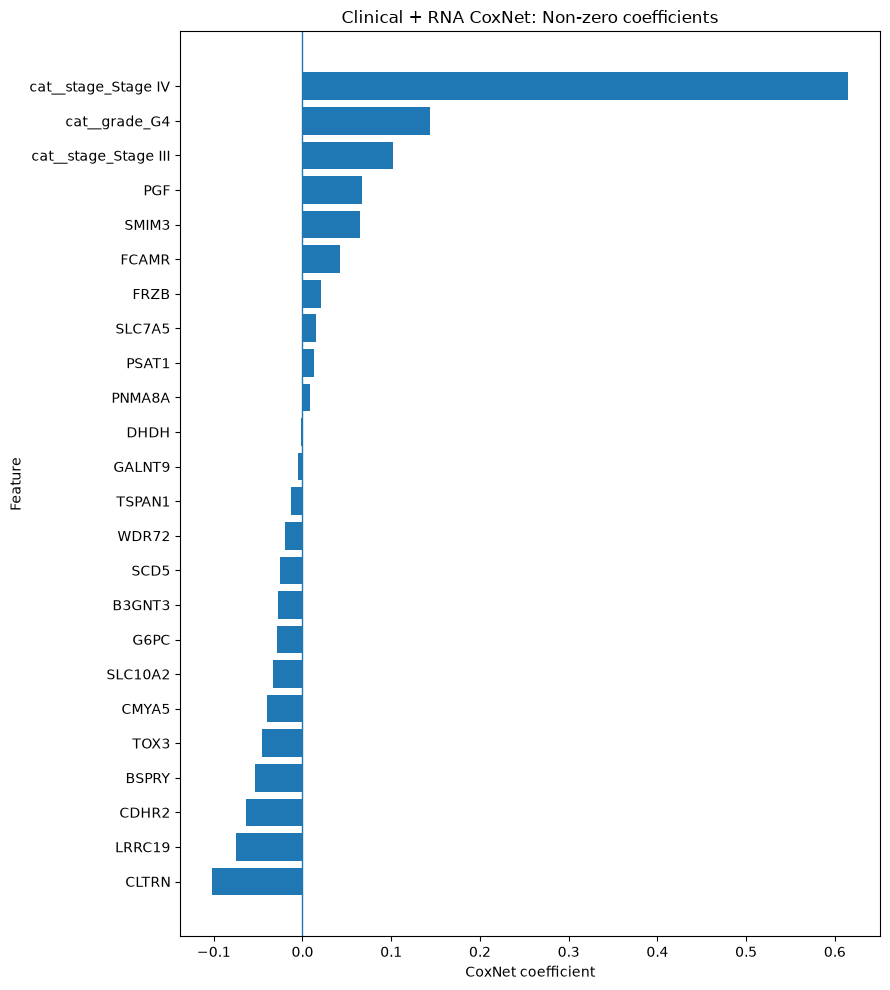

Saved: c:\kirc-genomic-prognosis\reports\figures\fig5_clinical_rna_nonzero_coefficients.png


In [8]:
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

fig_path = FIGURE_DIR / "fig5_clinical_rna_nonzero_coefficients.png"

plt.figure(figsize=(9, 10))

plt.barh(
    plot_df["display_name"],
    plot_df["coefficient"]
)

plt.axvline(0, linewidth=1)

plt.xlabel("CoxNet coefficient")
plt.ylabel("Feature")
plt.title("Clinical + RNA CoxNet: Non-zero coefficients")

plt.tight_layout()
plt.savefig(
    fig_path,
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Saved:", fig_path)

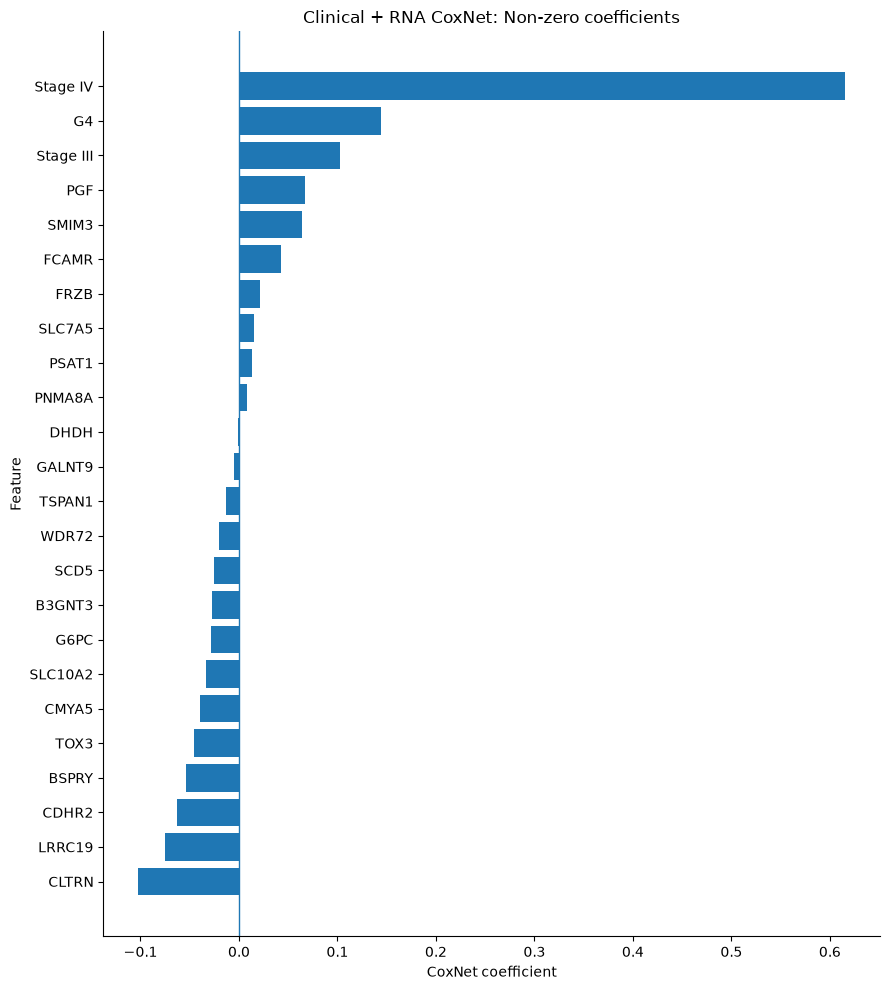

Saved: c:\kirc-genomic-prognosis\reports\figures\fig5_clinical_rna_nonzero_coefficients.png


In [9]:
import matplotlib.pyplot as plt

# ============================================================
# Figure 5. Clinical + RNA CoxNet non-zero coefficients
# ============================================================

plot_df = (
    xai_global
    .sort_values("coefficient", ascending=True)
    .copy()
)

# Clean clinical feature names for presentation
plot_df["display_name_clean"] = (
    plot_df["display_name"]
    .str.replace("cat__stage_", "", regex=False)
    .str.replace("cat__grade_", "", regex=False)
    .str.replace("cat__gender_", "", regex=False)
)

# Output directory
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

fig_path = (
    FIGURE_DIR
    / "fig5_clinical_rna_nonzero_coefficients.png"
)

# Plot
fig, ax = plt.subplots(figsize=(9, 10))

ax.barh(
    plot_df["display_name_clean"],
    plot_df["coefficient"]
)

# Zero reference line
ax.axvline(
    x=0,
    linewidth=1
)

# Labels
ax.set_xlabel("CoxNet coefficient")
ax.set_ylabel("Feature")
ax.set_title(
    "Clinical + RNA CoxNet: Non-zero coefficients"
)

# Remove unnecessary top/right borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Save
plt.savefig(
    fig_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fig_path)

## Patient-specific local explanation

Reconstruct the frozen Clinical + RNA preprocessing pipeline using
the original Train split only.

For each Test patient, feature-level contribution is defined as:

contribution = standardized feature value × CoxNet coefficient

The sum of feature contributions, together with the model offset,
must reproduce the frozen Clinical + RNA risk score.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sksurv.linear_model import CoxnetSurvivalAnalysis
from sksurv.util import Surv

# ============================================================
# Reconstruct frozen Train / Test data
# ============================================================

cohort = pd.read_parquet(
    PROCESSED_DIR / "kirc_modeling_cohort.parquet"
)

rna_tpm = pd.read_parquet(
    PROCESSED_DIR / "rna_tpm_modeling_raw.parquet"
)

splits = pd.read_csv(
    PROCESSED_DIR / "splits.csv"
)

train_ids = (
    splits.loc[
        splits["split"] == "train",
        "patient_id"
    ]
    .tolist()
)

test_ids = (
    splits.loc[
        splits["split"] == "test",
        "patient_id"
    ]
    .tolist()
)

train_df = (
    cohort
    .set_index("patient_id")
    .loc[train_ids]
    .reset_index()
)

test_df = (
    cohort
    .set_index("patient_id")
    .loc[test_ids]
    .reset_index()
)

print("Train:", train_df.shape)
print("Test :", test_df.shape)

assert len(train_df) == 370
assert len(test_df) == 80

Train: (370, 10)
Test : (80, 10)


In [11]:
# ============================================================
# RNA preprocessing — Train only
# ============================================================

rna_train_raw = rna_tpm.loc[train_ids].copy()
rna_test_raw = rna_tpm.loc[test_ids].copy()

# 1. Low-expression filter
min_samples = int(
    np.ceil(len(train_df) * 0.20)
)

expr_counts = (
    rna_train_raw >= 1.0
).sum(axis=0)

kept_genes = expr_counts[
    expr_counts >= min_samples
].index

assert min_samples == 74
assert len(kept_genes) == 14220

# 2. log2(TPM + 1)
rna_train_log = np.log2(
    rna_train_raw[kept_genes] + 1
)

rna_test_log = np.log2(
    rna_test_raw[kept_genes] + 1
)

# 3. Train MAD
train_median = rna_train_log.median(axis=0)

train_mad = (
    rna_train_log
    .sub(train_median, axis=1)
    .abs()
    .median(axis=0)
)

# 4. Top-500
top500_genes = (
    train_mad
    .sort_values(ascending=False)
    .head(500)
    .index
)

assert len(top500_genes) == 500

print("Low-expression filtered genes:", len(kept_genes))
print("Top RNA genes:", len(top500_genes))

Low-expression filtered genes: 14220
Top RNA genes: 500


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ============================================================
# Clinical + RNA 510-feature matrix reconstruction
# ============================================================

clinical_features = [
    "age",
    "gender",
    "stage",
    "grade"
]

# Clinical preprocessing
clin_preprocessor = ColumnTransformer(
    transformers=[
        (
            "age",
            "passthrough",
            ["age"]
        ),
        (
            "cat",
            OneHotEncoder(
                categories=[
                    ["MALE", "FEMALE"],
                    [
                        "Stage I",
                        "Stage II",
                        "Stage III",
                        "Stage IV",
                        "Unknown"
                    ],
                    [
                        "G1",
                        "G2",
                        "G3",
                        "G4",
                        "Unknown"
                    ]
                ],
                drop=[
                    "MALE",
                    "Stage I",
                    "G2"
                ],
                handle_unknown="ignore",
                sparse_output=False
            ),
            ["gender", "stage", "grade"]
        )
    ]
)

# Train에서만 fit
X_train_clin = clin_preprocessor.fit_transform(
    train_df[clinical_features]
)

# Test에는 transform만
X_test_clin = clin_preprocessor.transform(
    test_df[clinical_features]
)

clinical_feature_names = (
    clin_preprocessor.get_feature_names_out()
)

# RNA Top-500
X_train_rna = (
    rna_train_log[top500_genes]
    .to_numpy()
)

X_test_rna = (
    rna_test_log[top500_genes]
    .to_numpy()
)

# Clinical 10 + RNA 500
X_train_combined = np.hstack([
    X_train_clin,
    X_train_rna
])

X_test_combined = np.hstack([
    X_test_clin,
    X_test_rna
])

feature_names = (
    list(clinical_feature_names)
    + list(top500_genes)
)

# 전체 510개 feature를 Train 기준으로 scaling
combined_scaler = StandardScaler()

X_train_scaled = combined_scaler.fit_transform(
    X_train_combined
)

X_test_scaled = combined_scaler.transform(
    X_test_combined
)

print("Clinical Train:", X_train_clin.shape)
print("Clinical Test :", X_test_clin.shape)

print("RNA Train:", X_train_rna.shape)
print("RNA Test :", X_test_rna.shape)

print("Combined Train:", X_train_scaled.shape)
print("Combined Test :", X_test_scaled.shape)

assert X_train_clin.shape == (370, 10)
assert X_test_clin.shape == (80, 10)

assert X_train_rna.shape == (370, 500)
assert X_test_rna.shape == (80, 500)

assert X_train_scaled.shape == (370, 510)
assert X_test_scaled.shape == (80, 510)

print("\nPASS: 510-feature model input reconstructed.")

Clinical Train: (370, 10)
Clinical Test : (80, 10)
RNA Train: (370, 500)
RNA Test : (80, 500)
Combined Train: (370, 510)
Combined Test : (80, 510)

PASS: 510-feature model input reconstructed.


In [13]:
from sksurv.linear_model import CoxnetSurvivalAnalysis
from sksurv.util import Surv

# ============================================================
# Frozen Clinical + RNA CoxNet reproducibility check
# ============================================================

FINAL_L1_RATIO = 0.50
FINAL_ALPHA_IDX = 18
FROZEN_ALPHA = 0.1079631601142658

# Survival target
y_train = Surv.from_arrays(
    event=train_df["pfi_event"].astype(bool).to_numpy(),
    time=train_df["pfi_time"].astype(float).to_numpy()
)

# Frozen specification으로 재학습
xai_model = CoxnetSurvivalAnalysis(
    l1_ratio=FINAL_L1_RATIO,
    n_alphas=50,
    alpha_min_ratio=0.01,
    max_iter=100000
)

xai_model.fit(
    X_train_scaled,
    y_train
)

xai_alpha = xai_model.alphas_[FINAL_ALPHA_IDX]

# alpha 확인
assert np.isclose(
    xai_alpha,
    FROZEN_ALPHA,
    rtol=1e-8,
    atol=1e-10
)

# ------------------------------------------------------------
# Coefficient 재현 확인
# ------------------------------------------------------------

saved_coef = (
    clinical_rna_coef
    .set_index("feature")
    .loc[feature_names, "coefficient"]
    .to_numpy()
)

recomputed_coef = (
    xai_model.coef_[:, FINAL_ALPHA_IDX]
)

coef_max_diff = np.max(
    np.abs(saved_coef - recomputed_coef)
)

assert np.allclose(
    saved_coef,
    recomputed_coef,
    rtol=1e-8,
    atol=1e-10
)

# ------------------------------------------------------------
# Test risk score 재현 확인
# ------------------------------------------------------------

recomputed_test_risk = xai_model.predict(
    X_test_scaled,
    alpha=xai_alpha
)

# 환자 순서까지 반드시 동일해야 함
assert list(test_df["patient_id"]) == list(
    test_predictions["patient_id"]
)

saved_test_risk = (
    test_predictions["clinical_rna_risk"]
    .to_numpy()
)

risk_max_diff = np.max(
    np.abs(
        recomputed_test_risk
        - saved_test_risk
    )
)

assert np.allclose(
    recomputed_test_risk,
    saved_test_risk,
    rtol=1e-8,
    atol=1e-10
)

print("Frozen alpha:", xai_alpha)
print("Max coefficient difference:", coef_max_diff)
print("Max risk-score difference:", risk_max_diff)

print(
    "\nPASS: Frozen Clinical+RNA model "
    "and Test risk scores reproduced."
)

Frozen alpha: 0.1079631601142658
Max coefficient difference: 9.71445146547012e-17
Max risk-score difference: 4.440892098500626e-16

PASS: Frozen Clinical+RNA model and Test risk scores reproduced.


In [14]:
# ============================================================
# Patient-specific feature contributions
# contribution_ij = standardized_value_ij × coefficient_j
# ============================================================

# Frozen coefficient
beta = recomputed_coef.copy()

# Test contribution matrix
test_contributions = (
    X_test_scaled * beta
)

# DataFrame
contribution_df = pd.DataFrame(
    test_contributions,
    index=test_df["patient_id"],
    columns=feature_names
)

print("Contribution matrix:", contribution_df.shape)

assert contribution_df.shape == (80, 510)

Contribution matrix: (80, 510)


In [15]:
# ============================================================
# Check whether feature contributions reproduce model risk
# ============================================================

contribution_sum = (
    contribution_df
    .sum(axis=1)
    .to_numpy()
)

# predict()와 단순 contribution 합 사이의 차이 확인
risk_difference = (
    recomputed_test_risk
    - contribution_sum
)

print(
    "Difference min/max:",
    risk_difference.min(),
    risk_difference.max()
)

print(
    "Difference SD:",
    risk_difference.std()
)

Difference min/max: -4.440892098500626e-16 4.440892098500626e-16
Difference SD: 1.873538485101681e-16


In [16]:
# ============================================================
# Final local contribution reconstruction check
# ============================================================

contribution_sum = (
    contribution_df
    .sum(axis=1)
    .to_numpy()
)

risk_reconstruction_error = np.max(
    np.abs(
        contribution_sum
        - recomputed_test_risk
    )
)

print(
    "Max local risk reconstruction error:",
    risk_reconstruction_error
)

assert np.allclose(
    contribution_sum,
    recomputed_test_risk,
    rtol=1e-8,
    atol=1e-10
)

print(
    "\nPASS: Sum of feature contributions "
    "reproduces frozen Test risk."
)

Max local risk reconstruction error: 4.440892098500626e-16

PASS: Sum of feature contributions reproduces frozen Test risk.


In [17]:
# ============================================================
# Keep only non-zero coefficient features
# ============================================================

nonzero_mask = np.abs(beta) > 1e-12

nonzero_feature_names = np.array(
    feature_names
)[nonzero_mask]

contribution_nonzero_df = (
    contribution_df[
        nonzero_feature_names
    ]
    .copy()
)

print(
    "Non-zero contribution matrix:",
    contribution_nonzero_df.shape
)

assert contribution_nonzero_df.shape == (80, 24)

display(
    contribution_nonzero_df.head()
)

Non-zero contribution matrix: (80, 24)


,cat__stage_Stage III,cat__stage_Stage IV,cat__grade_G4,ENSG00000125255.7,ENSG00000074276.10,ENSG00000119630.14,ENSG00000135069.14,ENSG00000104808.8,ENSG00000117472.10,ENSG00000184434.8,...,ENSG00000103257.9,ENSG00000182870.13,ENSG00000131482.10,ENSG00000256235.2,ENSG00000164309.15,ENSG00000147003.7,ENSG00000162998.5,ENSG00000182013.18,ENSG00000103460.17,ENSG00000166415.15
patient_id,,,,,,,,,,,,,,,,,,,,,
TCGA-BP-5169,-0.058529,-0.251487,0.364596,0.048940,0.090608,0.033455,-0.001072,0.000681,0.023526,0.133283,...,0.002688,0.006722,0.025647,0.033844,0.058619,0.172781,-0.039717,-0.013858,0.052163,0.042435
TCGA-BP-4353,-0.058529,-0.251487,-0.056968,-0.023579,0.036944,0.115080,-0.002103,0.001252,-0.009678,0.057787,...,-0.004062,-0.002530,0.027109,0.112758,0.014901,0.020810,-0.013229,0.009284,0.046348,-0.003065
TCGA-BP-5200,-0.058529,-0.251487,0.364596,-0.007111,-0.071959,0.005325,-0.009536,-0.001777,0.011264,0.042241,...,0.008224,-0.008142,-0.005037,-0.025606,-0.008319,-0.030591,0.002130,0.002998,0.052682,-0.006585
TCGA-B0-5121,-0.058529,-0.251487,-0.056968,-0.009845,0.041984,-0.026852,-0.011981,0.000829,-0.001443,0.034286,...,-0.014844,0.003296,0.010299,-0.038912,0.060169,-0.018605,-0.014260,-0.015007,0.047915,0.009614
TCGA-B4-5378,-0.058529,-0.251487,-0.056968,0.044860,0.078331,-0.014913,-0.014114,0.000571,0.006614,0.120385,...,0.029728,-0.005698,0.027037,0.142585,-0.020381,0.180198,0.038986,0.004849,-0.136136,-0.012629


In [18]:
# ============================================================
# Select representative Test patients
# using predicted risk only
# ============================================================

risk_table = test_predictions[
    [
        "patient_id",
        "clinical_rna_risk"
    ]
].copy()

target_quantiles = {
    "Low": 0.10,
    "Middle": 0.50,
    "High": 0.90
}

selected_rows = []

for group, q in target_quantiles.items():

    target_risk = (
        risk_table["clinical_rna_risk"]
        .quantile(q)
    )

    idx = (
        risk_table["clinical_rna_risk"]
        .sub(target_risk)
        .abs()
        .idxmin()
    )

    selected_rows.append({
        "risk_group": group,
        "patient_id": risk_table.loc[idx, "patient_id"],
        "clinical_rna_risk":
            risk_table.loc[idx, "clinical_rna_risk"],
        "target_quantile": q
    })

selected_patients = pd.DataFrame(
    selected_rows
)

display(selected_patients)

,risk_group,patient_id,clinical_rna_risk,target_quantile
0,Low,TCGA-B0-5119,-0.783538,0.1
1,Middle,TCGA-CZ-5458,-0.287216,0.5
2,High,TCGA-B0-4845,1.702245,0.9


In [19]:
# ============================================================
# Clean feature labels for Local XAI
# ============================================================

feature_label_df = (
    clinical_rna_nonzero
    .merge(
        clinical_rna_genes[["feature", "gene_name"]],
        on="feature",
        how="left"
    )
)

feature_label_df["display_name"] = (
    feature_label_df["gene_name"]
    .fillna(feature_label_df["feature"])
)

feature_label_df["display_name"] = (
    feature_label_df["display_name"]
    .str.replace("cat__stage_", "", regex=False)
    .str.replace("cat__grade_", "", regex=False)
    .str.replace("cat__gender_", "", regex=False)
    .str.replace("age__age", "Age", regex=False)
)

feature_label_map = dict(
    zip(
        feature_label_df["feature"],
        feature_label_df["display_name"]
    )
)

feature_label_df[
    ["feature", "display_name", "feature_type"]
]

,feature,display_name,feature_type
0,cat__stage_Stage IV,Stage IV,Clinical
1,cat__grade_G4,G4,Clinical
2,cat__stage_Stage III,Stage III,Clinical
3,ENSG00000147003.7,CLTRN,RNA
4,ENSG00000184434.8,LRRC19,RNA
5,ENSG00000119630.14,PGF,RNA
6,ENSG00000256235.2,SMIM3,RNA
7,ENSG00000074276.10,CDHR2,RNA
8,ENSG00000119411.11,BSPRY,RNA
9,ENSG00000103460.17,TOX3,RNA


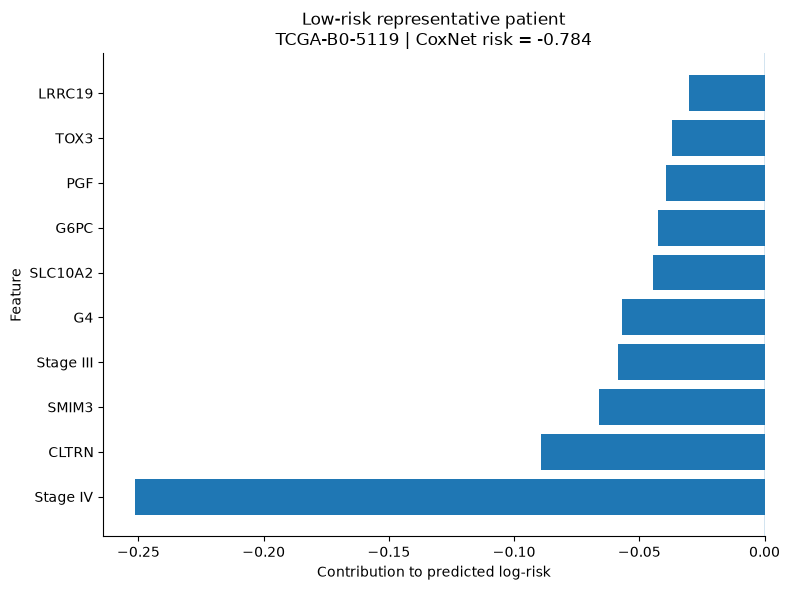

Saved: c:\kirc-genomic-prognosis\reports\figures\fig6_low_risk_local_contributions.png


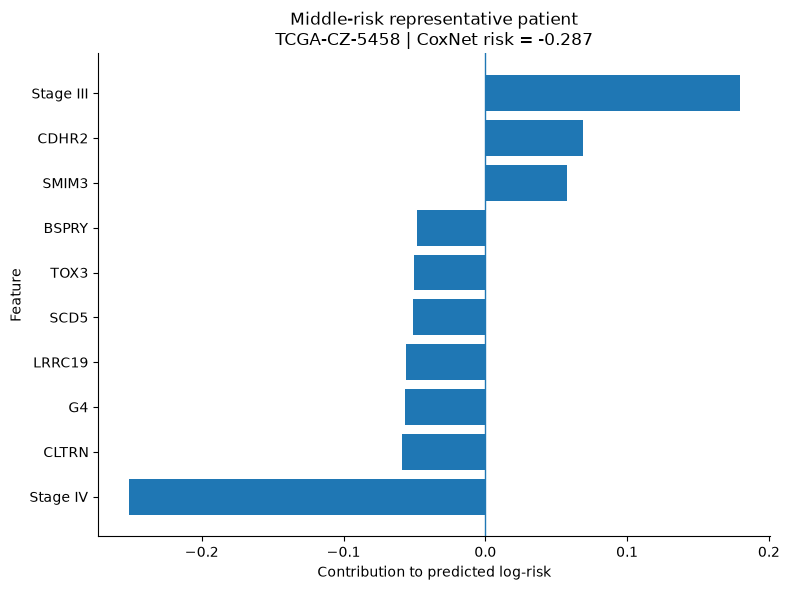

Saved: c:\kirc-genomic-prognosis\reports\figures\fig6_middle_risk_local_contributions.png


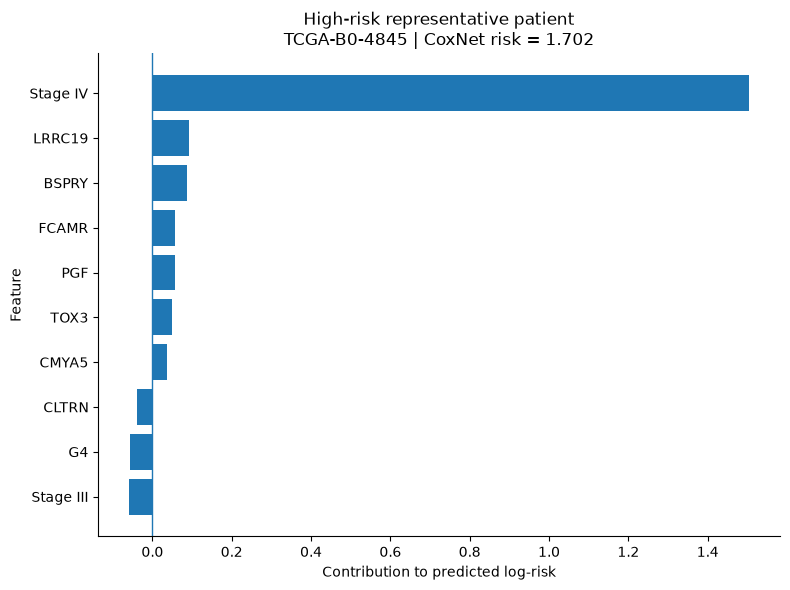

Saved: c:\kirc-genomic-prognosis\reports\figures\fig6_high_risk_local_contributions.png


In [20]:
# ============================================================
# Figure 6. Patient-specific Local XAI
# Top 10 absolute contributions for representative patients
# ============================================================

FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

TOP_N = 10

for _, row in selected_patients.iterrows():

    risk_group = row["risk_group"]
    patient_id = row["patient_id"]
    risk_score = row["clinical_rna_risk"]

    # 24 non-zero feature contributions
    patient_contrib = (
        contribution_nonzero_df
        .loc[patient_id]
        .copy()
    )

    # Top 10 by absolute contribution
    top_features = (
        patient_contrib
        .abs()
        .sort_values(ascending=False)
        .head(TOP_N)
        .index
    )

    plot_patient = (
        patient_contrib
        .loc[top_features]
        .sort_values()
        .to_frame("contribution")
        .reset_index()
        .rename(columns={"index": "feature"})
    )

    plot_patient["display_name"] = (
        plot_patient["feature"]
        .map(feature_label_map)
        .fillna(plot_patient["feature"])
    )

    # Plot
    fig, ax = plt.subplots(figsize=(8, 6))

    ax.barh(
        plot_patient["display_name"],
        plot_patient["contribution"]
    )

    ax.axvline(
        0,
        linewidth=1
    )

    ax.set_xlabel(
        "Contribution to predicted log-risk"
    )

    ax.set_ylabel("Feature")

    ax.set_title(
        f"{risk_group}-risk representative patient\n"
        f"{patient_id} | CoxNet risk = {risk_score:.3f}"
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()

    filename = (
        f"fig6_{risk_group.lower()}_risk_local_contributions.png"
    )

    fig_path = FIGURE_DIR / filename

    plt.savefig(
        fig_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", fig_path)

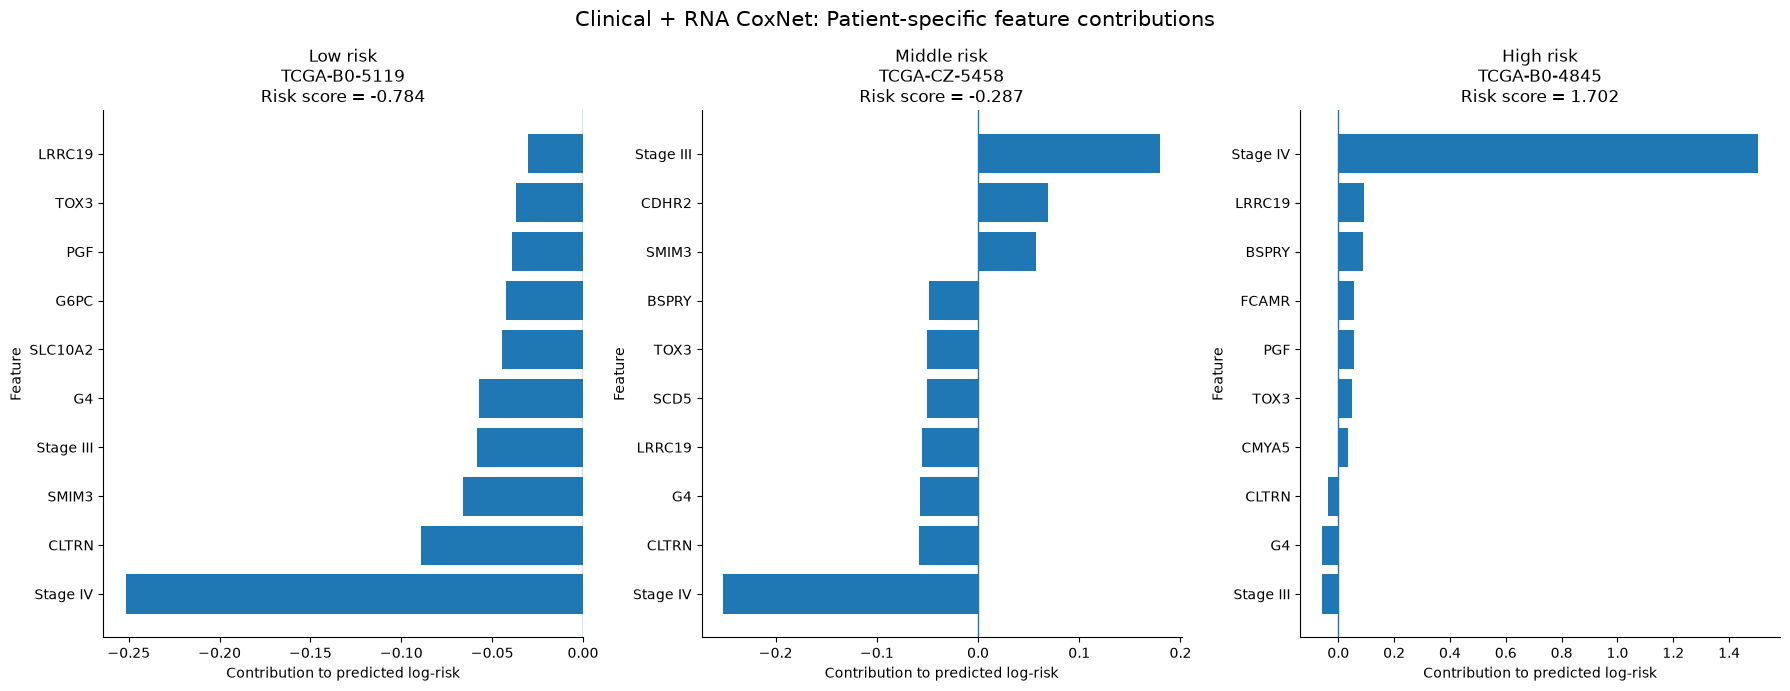

Saved: c:\kirc-genomic-prognosis\reports\figures\fig6_clinical_rna_local_explanations.png


In [21]:
# ============================================================
# Figure 6. Local explanations for representative patients
# ============================================================

fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(18, 7)
)

TOP_N = 10

for ax, (_, row) in zip(
    axes,
    selected_patients.iterrows()
):
    risk_group = row["risk_group"]
    patient_id = row["patient_id"]
    risk_score = row["clinical_rna_risk"]

    patient_contrib = (
        contribution_nonzero_df
        .loc[patient_id]
        .copy()
    )

    # Top 10 by absolute contribution
    top_features = (
        patient_contrib
        .abs()
        .sort_values(ascending=False)
        .head(TOP_N)
        .index
    )

    plot_patient = (
        patient_contrib
        .loc[top_features]
        .sort_values()
        .to_frame("contribution")
        .reset_index()
        .rename(columns={"index": "feature"})
    )

    plot_patient["display_name"] = (
        plot_patient["feature"]
        .map(feature_label_map)
        .fillna(plot_patient["feature"])
    )

    ax.barh(
        plot_patient["display_name"],
        plot_patient["contribution"]
    )

    ax.axvline(
        0,
        linewidth=1
    )

    ax.set_title(
        f"{risk_group} risk\n"
        f"{patient_id}\n"
        f"Risk score = {risk_score:.3f}"
    )

    ax.set_xlabel(
        "Contribution to predicted log-risk"
    )

    ax.set_ylabel("Feature")

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Clinical + RNA CoxNet: Patient-specific feature contributions",
    fontsize=15
)

plt.tight_layout()

fig_path = (
    FIGURE_DIR
    / "fig6_clinical_rna_local_explanations.png"
)

plt.savefig(
    fig_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", fig_path)